# Metacatalog classifications

Aggregate unique cross-match associations from
`metacatalog_associations.parquet` (written by radio / optical / x-ray
crossmatch notebooks). Harmonize native labels into a coarse taxonomy, flag
per-`meta_id` conflicts, and visualize the mix.

**Does not re-run crossmatches.** Re-run the individual notebooks to refresh
association rows (replace-by-`catalog`).

| Harmonized | Typical sources |
| --- | --- |
| `star` | Freund2022; MilliQuas `S`; eRASS negative `class_gal_exgal` |
| `galaxy` | NEDLVS; eRASS positive codes |
| `agn` | MilliQuas `Q`/`A`/`B`/`K`/`N`; eRASS blazar |
| `cluster` | Xu2022 |
| `xray` | 2RXS; eRASS without class |
| `radio` | VLSSR / NVSS / VLASS / LoDeSS |
| `unknown` | unrecognized native label |

**Conflict:** a `meta_id` with ≥2 distinct harmonized labels keeps all evidence
rows; the summary marks `conflict=True`.

**Run cells in order.** Reload from disk / restart the kernel after API changes.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from lwa_catalog import CatalogLayout
from lwa_catalog.analyze import (
    flag_association_conflicts,
    harmonize_associations,
    read_associations,
    summarize_classifications,
    summarize_classifications_text,
)

# --- operator config ---
CATALOG_DIR = Path("/fast/claw/metacatalog_healpix_IdTR-0.75s_subband/")
# Optional subset of catalog ids, e.g. ("eRASS3", "MilliQuas", "Freund2022").
# None keeps every catalog present in the associations table.
CATALOG_FILTER: tuple[str, ...] | None = None
# How many conflicting meta_ids to show in the sample table.
CONFLICT_SAMPLE_N = 40

layout = CatalogLayout(CATALOG_DIR)
ASSOCIATIONS_PATH = layout.metacatalog_associations()

print("CATALOG_DIR =", layout.root.resolve())
print("ASSOCIATIONS_PATH =", ASSOCIATIONS_PATH.resolve())
print(
    "associations exists:" if ASSOCIATIONS_PATH.is_file() else "associations MISSING:",
    ASSOCIATIONS_PATH.resolve(),
)
print("CATALOG_FILTER =", CATALOG_FILTER)


CATALOG_DIR = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband
ASSOCIATIONS_PATH = /fast/claw/metacatalog_healpix_IdTR-0.75s_subband/metacatalog_associations.parquet
associations exists: /fast/claw/metacatalog_healpix_IdTR-0.75s_subband/metacatalog_associations.parquet
CATALOG_FILTER = None


## Load associations

Reads the shared long-form table. Optionally filters to `CATALOG_FILTER`.
Adds `class_harmonized` for downstream tables / plots.


In [2]:
assoc_raw = read_associations(layout)
if assoc_raw.empty:
    raise FileNotFoundError(
        f"No associations rows at {ASSOCIATIONS_PATH.resolve()}. "
        "Run crossmatch notebooks with WRITE_ASSOCIATIONS / WRITE_CROSSMATCH first."
    )

if CATALOG_FILTER is not None:
    wanted = {str(c) for c in CATALOG_FILTER}
    assoc = assoc_raw.loc[assoc_raw["catalog"].astype(str).isin(wanted)].copy()
else:
    assoc = assoc_raw.copy()

if assoc.empty:
    raise ValueError(f"No rows left after CATALOG_FILTER={CATALOG_FILTER}")

assoc = harmonize_associations(assoc)
conflicts = flag_association_conflicts(assoc)
print(summarize_classifications_text(assoc))
print(f"\nrows after filter: {len(assoc):,}  catalogs={sorted(assoc['catalog'].astype(str).unique())}")


Associations:                  40280
Unique meta_id:                27716
Catalogs:                         10
Conflict meta_ids:              3862
Harmonized:
  radio         30071
  galaxy         4172
  agn            2741
  xray           2336
  unknown         578
  star            217
  cluster         165

rows after filter: 40,280  catalogs=['2RXS', 'Freund2022', 'LoDeSS', 'MilliQuas', 'NEDLVS', 'NVSS', 'VLASS', 'VLSSR', 'Xu2022', 'eRASS3']


## Native class counts by catalog


In [3]:
native_counts = (
    assoc.groupby(["catalog", "class_native"], dropna=False)
    .size()
    .rename("n")
    .reset_index()
    .sort_values(["catalog", "n"], ascending=[True, False])
)
display(native_counts)

harmonized_counts = (
    assoc["class_harmonized"]
    .astype(str)
    .value_counts(dropna=False)
    .rename("n")
    .to_frame()
)
display(harmonized_counts)


,catalog,class_native,n
0,2RXS,2RXS,2336
1,Freund2022,Freund2022,172
2,LoDeSS,LoDeSS,3211
9,MilliQuas,Q,2110
5,MilliQuas,A,296
10,MilliQuas,R,294
8,MilliQuas,N,214
11,MilliQuas,R2,162
6,MilliQuas,B,83
15,MilliQuas,X,40


,n
class_harmonized,
radio,30071
galaxy,4172
agn,2741
xray,2336
unknown,578
star,217
cluster,165


## Conflict sample

`meta_id`s with ≥2 distinct harmonized labels. All association evidence rows for
those ids are listed (capped by `CONFLICT_SAMPLE_N` meta ids).


In [4]:
conflict_ids = conflicts.loc[conflicts["conflict"], "meta_id"]
print(f"conflict meta_ids: {len(conflict_ids):,} / {len(conflicts):,}")
display(conflicts.loc[conflicts["conflict"]].head(CONFLICT_SAMPLE_N))

if len(conflict_ids):
    sample_ids = set(conflict_ids.head(CONFLICT_SAMPLE_N).tolist())
    conflict_rows = assoc.loc[assoc["meta_id"].isin(sample_ids)].sort_values(
        ["meta_id", "catalog"]
    )
    display(
        conflict_rows[
            [
                c
                for c in (
                    "meta_id",
                    "catalog",
                    "ref_id",
                    "class_native",
                    "class_harmonized",
                    "sep_arcsec",
                )
                if c in conflict_rows.columns
            ]
        ]
    )
else:
    print("No conflicts under the current filter.")


conflict meta_ids: 3,862 / 27,716


,meta_id,n_associations,n_harmonized,harmonized_labels,conflict
3,11,3,3,"galaxy,radio,xray",True
5,16,2,2,"cluster,star",True
8,23,4,3,"agn,radio,xray",True
9,29,2,2,"radio,xray",True
10,36,3,2,"galaxy,radio",True
11,46,2,2,"star,xray",True
13,53,3,3,"agn,radio,xray",True
14,54,3,3,"agn,radio,xray",True
15,55,2,2,"cluster,xray",True
16,57,2,2,"star,xray",True


,meta_id,catalog,ref_id,class_native,class_harmonized,sep_arcsec
37946,11,2RXS,2RXS J221427.2-170134,2RXS,xray,26.917900
30072,11,NEDLVS,3C 444,G,galaxy,7.489543
1,11,VLSSR,"333.606370,-17.028144",VLSSR,radio,10.796256
37607,16,Freund2022,2RXS J151559.6+071006,Freund2022,star,855.095425
37780,16,Xu2022,600,B,cluster,13.397335
...,...,...,...,...,...,...
32986,197,MilliQuas,3C 341,A,agn,9.376498
60,197,VLSSR,"247.013662,27.694648",VLSSR,radio,0.000000
37985,200,2RXS,2RXS J113910.5-135027,2RXS,xray,23.892476
22590,200,VLASS,"174.794030,-13.845416",VLASS,radio,8.391291


## Harmonized class pie


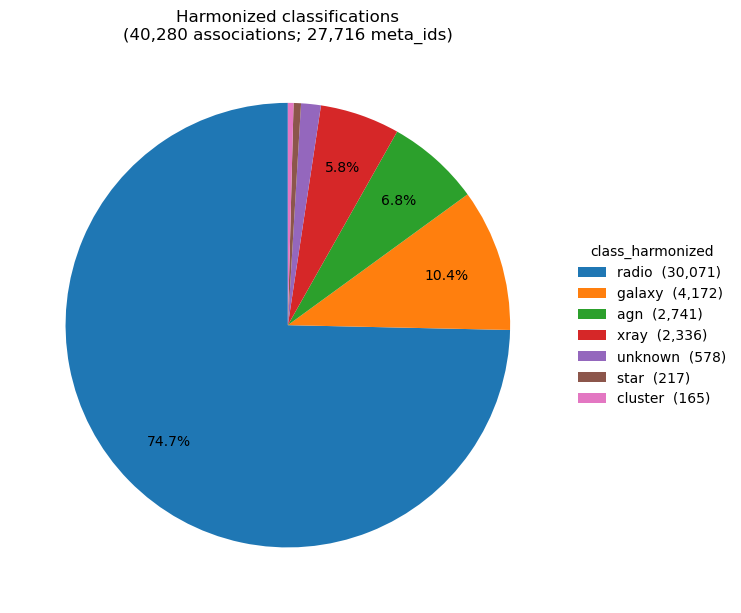

In [5]:
%matplotlib inline

counts = assoc["class_harmonized"].astype(str).value_counts(dropna=False)
if counts.empty:
    print("Nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(7.5, 7.5))
    wedges, _texts, _autotexts = ax.pie(
        counts.to_numpy(dtype=float),
        labels=None,
        autopct=lambda p: f"{p:.1f}%" if p >= 2.0 else "",
        startangle=90,
        pctdistance=0.75,
    )
    ax.legend(
        wedges,
        [f"{lab}  ({int(n):,})" for lab, n in counts.items()],
        title="class_harmonized",
        loc="center left",
        bbox_to_anchor=(1.0, 0.5),
        frameon=False,
    )
    ax.set_title(
        f"Harmonized classifications\n"
        f"({len(assoc):,} associations; {assoc['meta_id'].nunique():,} meta_ids)"
    )
    plt.tight_layout()
    plt.show()


## Catalog × harmonized stacked bar


class_harmonized,agn,cluster,galaxy,radio,star,unknown,xray
catalog,,,,,,,
2RXS,0,0,0,0,0,0,2336
Freund2022,0,0,0,0,172,0,0
LoDeSS,0,0,0,3211,0,0,0
MilliQuas,2741,0,0,0,1,578,0
NEDLVS,0,0,2887,0,0,0,0
NVSS,0,0,0,7773,0,0,0
VLASS,0,0,0,4284,0,0,0
VLSSR,0,0,0,14803,0,0,0
Xu2022,0,165,0,0,0,0,0


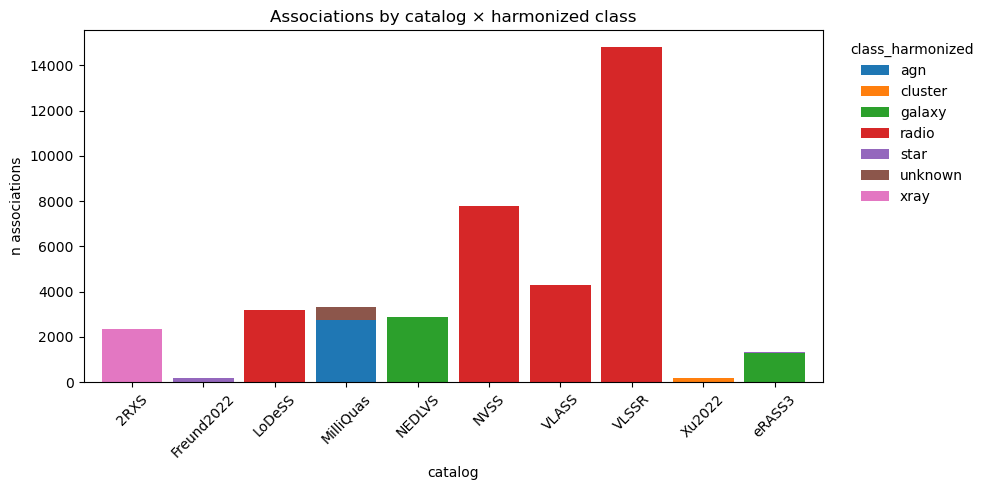

In [6]:
cross = (
    assoc.groupby(["catalog", "class_harmonized"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .sort_index()
)
display(cross)

if cross.empty:
    print("Nothing to plot.")
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    cross.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_xlabel("catalog")
    ax.set_ylabel("n associations")
    ax.set_title("Associations by catalog × harmonized class")
    ax.legend(title="class_harmonized", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()


## Conflict-only subset (optional)

Same stacked bar restricted to associations whose `meta_id` is in conflict.


conflict associations: 10,032


class_harmonized,agn,cluster,galaxy,radio,star,unknown,xray
catalog,,,,,,,
2RXS,0,0,0,0,0,0,1247
Freund2022,0,0,0,0,146,0,0
LoDeSS,0,0,0,525,0,0,0
MilliQuas,1674,0,0,0,1,273,0
NEDLVS,0,0,993,0,0,0,0
NVSS,0,0,0,1159,0,0,0
VLASS,0,0,0,669,0,0,0
VLSSR,0,0,0,2452,0,0,0
Xu2022,0,111,0,0,0,0,0


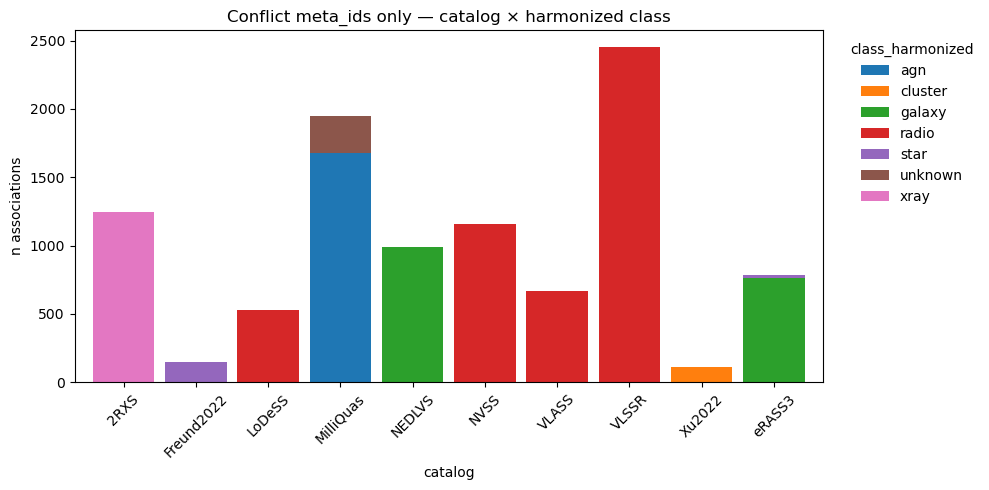

In [7]:
conflict_id_set = set(conflicts.loc[conflicts["conflict"], "meta_id"].tolist())
conflict_assoc = assoc.loc[assoc["meta_id"].isin(conflict_id_set)].copy()
print(f"conflict associations: {len(conflict_assoc):,}")

if conflict_assoc.empty:
    print("No conflict associations to plot.")
else:
    cross_c = (
        conflict_assoc.groupby(["catalog", "class_harmonized"], dropna=False)
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )
    display(cross_c)
    fig, ax = plt.subplots(figsize=(10, 5))
    cross_c.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_xlabel("catalog")
    ax.set_ylabel("n associations")
    ax.set_title("Conflict meta_ids only — catalog × harmonized class")
    ax.legend(title="class_harmonized", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    ax.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()
